In [128]:
from dotenv import load_dotenv
load_dotenv()

True

In [129]:
from langgraph.graph import START,END, StateGraph
from langchain_groq import ChatGroq
from pydantic import BaseModel
from langgraph.types import interrupt,Command
from langgraph.checkpoint.memory import InMemorySaver
from typing import Literal

In [130]:
class MainState(BaseModel):
    query:str = ""
    draft:str = ""
    human_feedback: str = ""
    final_response: str = ""

In [131]:
llm = ChatGroq(model="openai/gpt-oss-20b")

In [132]:
# Defining the nodes

def draft_email(state: MainState) -> MainState:
    if state.human_feedback:
        draft = llm.invoke(f"""
            Rewrite the draft email for {state.query}.
            You have generated this draft mail: {state.draft}.
            Human Feedback to Apply: {state.human_feedback}
        """)
        state.draft = draft.content
    else:
        draft = llm.invoke(state.query)
        state.draft = draft.content
    return state

def human_feedback(state:MainState) -> MainState:
    feedback = interrupt({
        "draft_email":state.draft,
        "question":"Do you want to continue or re-write the mail ?"
    })
    fb = (feedback or "").strip().lower()
    if fb in ("approved",'ok','yes'):
        state.human_feedback = ""
        return state
    else:
        state.human_feedback = feedback
        return state

def finalize_node(state: MainState) -> MainState:
    if state.human_feedback:
        state.final_response = state.human_feedback
        return state
    else:
        print("email Sent Successfully")
        state.final_response = "Email Sent SuccessFully"
        return state

def condition_routing(state:MainState) -> Literal["draft_email","finalize_node"]:
    if state.human_feedback:
        return 'draft_email'
    return 'finalize_node'

In [133]:
graph_builder = StateGraph(MainState)

# node
graph_builder.add_node('draft_email',draft_email)
graph_builder.add_node('human_feedback',human_feedback)
graph_builder.add_node('finalize_node',finalize_node)

# edges
graph_builder.add_edge(START,'draft_email')
graph_builder.add_edge('draft_email','human_feedback')
graph_builder.add_conditional_edges('human_feedback',condition_routing)
graph_builder.add_edge('finalize_node',END)

graph = graph_builder.compile(checkpointer=InMemorySaver())

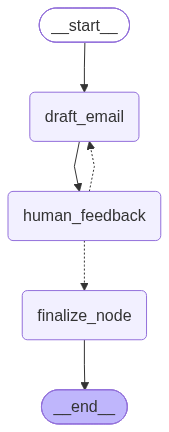

In [134]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [135]:
config = {"configurable":{"thread_id":"123d"}}
res = graph.invoke({"query":"I want to send a email for Resignation to my HR which should be started from 26 October 2026 and a 30 days notice period"},config=config)

In [136]:
print(res["draft"])

**Subject:** Notice of Resignation – Effective 26 October 2026

Dear [HR Manager’s Name],

I am writing to formally tender my resignation from my position as [Your Position] at [Company Name], effective 26 October 2026. In accordance with my employment contract, I am providing a 30‑day notice period, making my last working day 25 November 2026.

I am grateful for the opportunities and experiences I have gained during my time with the company. I am committed to ensuring a smooth transition and will gladly assist in handing over my responsibilities, training a replacement, or completing any outstanding projects before my departure.

Please let me know what steps you would like me to take during this notice period or if there are any specific tasks you would like me to prioritize.

Thank you for your support and understanding. I look forward to staying in touch and wish the team continued success.

Kind regards,

[Your Full Name]  
[Your Job Title]  
[Department]  
[Phone Number]  
[Email

In [137]:
res = graph.invoke(Command(resume="Make the mail short in less than 80 words"),config=config)

In [140]:
print(res["draft"])

**Subject:** Notice of Resignation – Effective 26 October 2026  

Dear [HR Manager’s Name],

I resign from my role as [Your Position] effective 26 October 2026, giving a 30‑day notice. My last working day will be 25 November 2026. I appreciate the opportunities and will assist with the transition.

Thank you for your support.

[Your Full Name]  
[Your Job Title]  
[Phone] | [Email]


In [141]:
res = graph.invoke(Command(resume="lets do one think change the Date from 26 to 28"),config=config)

In [143]:
print(res)

{'query': 'I want to send a email for Resignation to my HR which should be started from 26 October 2026 and a 30 days notice period', 'draft': '**Subject:** Notice of Resignation – Effective 28\u202fOctober\u202f2026  \n\nDear [HR Manager’s Name],\n\nI am writing to formally resign from my position as **[Your Position]**, effective **28\u202fOctober\u202f2026**. In accordance with my employment agreement, I will provide a 30‑day notice, making my last working day **27\u202fNovember\u202f2026**.\n\nI am grateful for the opportunities and support I have received during my time here, and I am committed to ensuring a smooth transition. I will gladly assist in training a replacement, documenting ongoing projects, and completing any outstanding tasks.\n\nThank you for your understanding and for the valuable experiences I have gained.\n\nSincerely,\n\n[Your Full Name]  \n[Your Job Title]  \n[Phone] | [Email]', 'human_feedback': 'lets do one think change the Date from 26 to 28', 'final_respons

In [144]:
res = graph.invoke(Command(resume="ok"),config=config)

email Sent Successfully


In [145]:
print(res)

{'query': 'I want to send a email for Resignation to my HR which should be started from 26 October 2026 and a 30 days notice period', 'draft': '**Subject:** Notice of Resignation – Effective 28\u202fOctober\u202f2026  \n\nDear [HR Manager’s Name],\n\nI am writing to formally resign from my position as **[Your Position]**, effective **28\u202fOctober\u202f2026**. In accordance with my employment agreement, I will provide a 30‑day notice, making my last working day **27\u202fNovember\u202f2026**.\n\nI am grateful for the opportunities and support I have received during my time here, and I am committed to ensuring a smooth transition. I will gladly assist in training a replacement, documenting ongoing projects, and completing any outstanding tasks.\n\nThank you for your understanding and for the valuable experiences I have gained.\n\nSincerely,\n\n[Your Full Name]  \n[Your Job Title]  \n[Phone] | [Email]', 'human_feedback': '', 'final_response': 'Email Sent SuccessFully'}
